# Barrier sets give the same trend
Mean olefin length vs T, 50 bar, cat = 1e-1, 1 h, pocket crowding.

`tetra`: Flory-Schulz approximation, tetramerization barriers for all steps. `bep`: BEP barriers. `legacy`: original list.

Only the barrier set differs. Absolute values differ, the trends match.

In [1]:
import sys
sys.path.insert(0, '../scripts')
import warnings; warnings.filterwarnings('ignore')
import km_common as km
import pandas as pd
import matplotlib.pyplot as plt

P = 50                  # bar
SITE_FRAC = 10.0        # cat = 1e-1
T = list(range(300, 491, 10))
assert all(km.network_consistency(t, P)[0] for t in T)   # network valid
VARIANTS = {'tetra': dict(elim_map='tetra'),
            'bep': dict(elim_map='bep'),
            'legacy': dict(elim_map='legacy')}
CASES = {'batch, no diffusion limit': ('batch', None),
         'batch, 1000 um': ('batch', 1e6),
         'flow, 1000 um': ('flow', 1e6)}

In [2]:
# mean n, 1 h
rows = []
for case, (mode, size) in CASES.items():
    for name, kw in VARIANTS.items():
        for t in T:
            dist, _ = km.simulate(t, P, mode=mode, particle_nm=size, model='corrected', hours=1.0, n_steps=300,
                                  crowding='pocket', site_frac=SITE_FRAC, check_network=None, **kw)
            rows.append((case, name, t, km.mean_length(dist)))
res = pd.DataFrame(rows, columns=['case', 'variant', 'T', 'mean_n'])
res.pivot_table(index=['case', 'variant'], columns='T', values='mean_n').round(1)

T                                   300   310   320   330   340   350   360  \
case                      variant                                             
batch, 1000 um            bep       7.6   7.9   7.3   7.0   6.9   6.9   6.9   
                          legacy   14.9  13.6  11.7  10.3   9.7   9.6   9.7   
                          tetra    14.8  13.4  11.4   9.9   9.3   9.2   9.3   
batch, no diffusion limit bep       7.3   8.5   8.8   8.2   7.5   6.9   6.4   
                          legacy   15.7  15.9  16.0  16.0  16.0  15.2  13.7   
                          tetra    15.6  15.9  16.0  15.9  15.0  13.5  11.9   
flow, 1000 um             bep       5.1   5.4   6.3   6.9   7.4   7.8   8.3   
                          legacy   14.1  12.4  10.8   9.7   9.2   9.2   9.3   
                          tetra    14.2  12.3  10.5   9.3   8.8   8.9   9.0   

T                                   370   380  390  400   410   420   430  \
case                      variant                                           
batch, 1000 um            bep       6.7   6.6  6.5  6.4   6.6   7.6  10.0   
                          legacy    9.7   9.9  9.8  9.6   9.6   9.9  11.5   
                          tetra     9.3   9.4  9.3  9.1   9.3  10.4  13.3   
batch, no diffusion limit bep       5.9   5.6  5.3  5.0   4.9   5.2   6.1   
                          legacy   12.1  10.7  9.5  8.6   8.1   8.0   9.1   
                          tetra    10.5   9.3  8.4  7.7   7.6   8.8  12.4   
flow, 1000 um             bep       8.7   9.0  9.3  9.6   9.8  10.0  10.2   
                          legacy    9.4   9.7  9.8  9.9  10.1  10.3  10.4   
                          tetra     9.1   9.3  9.5  9.6   9.9  10.0  10.1   

T                                   440   450   460   470   480   490  
case                      variant                                      
batch, 1000 um            bep      13.8  14.7  15.1  15.2  15.1  14.9  
                          legacy   14.0  14.8  15.1  15.2  15.1  15.0  
                          tetra    14.9  15.4  15.5  15.5  15.4  15.3  
batch, no diffusion limit bep       8.5  12.7  13.9  13.4  12.8  12.1  
                          legacy   12.0  14.1  14.2  13.8  13.4  12.8  
                          tetra    14.7  15.0  14.8  14.5  14.2  13.9  
flow, 1000 um             bep      10.5  10.7  10.8  11.1  11.2  11.4  
                          legacy   10.7  10.8  10.9  11.3  11.4  11.5  
                          tetra    10.4  10.6  10.7  11.0  11.2  11.3

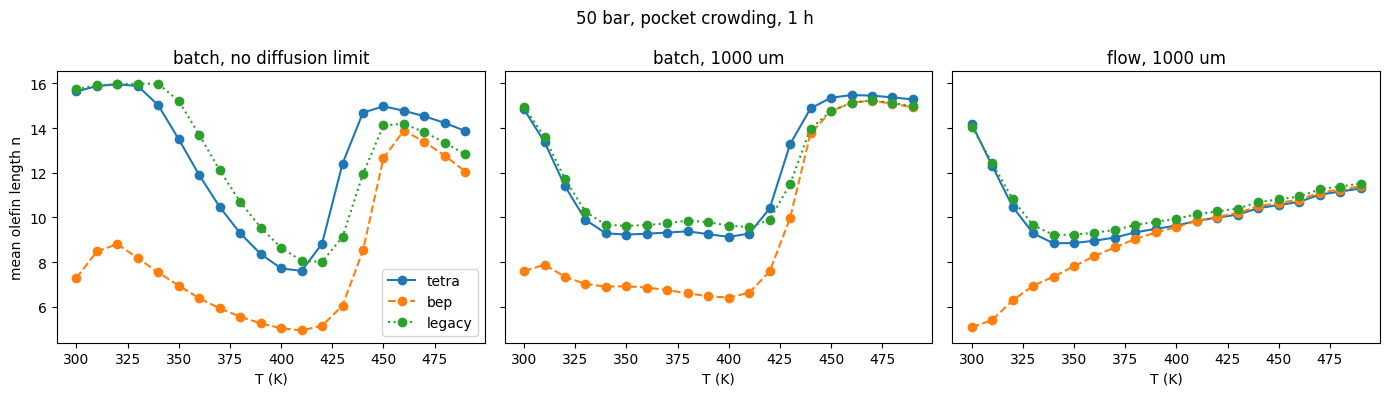

In [3]:
# n vs T
styles = {'tetra': ('C0', '-'), 'bep': ('C1', '--'), 'legacy': ('C2', ':')}
fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (case, g) in zip(axs, res.groupby('case', sort=False)):
    for name, h in g.groupby('variant', sort=False):
        ax.plot(h['T'], h['mean_n'], color=styles[name][0], ls=styles[name][1], marker='o', label=name)
    ax.set_title(case); ax.set_xlabel('T (K)')
axs[0].set_ylabel('mean olefin length n'); axs[0].legend()
fig.suptitle(f'{P} bar, pocket crowding, 1 h')
plt.tight_layout()